In [1]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# === 1. Parameters ===
tickers = ["AAPL", "MSFT", "NVDA", "AMZN", "META", "GOOGL", "TSLA"]
equal_weight = 1 / len(tickers)

In [3]:
# === 2. Download Adjusted Close Data ===
data = yf.download(tickers, period="10y", interval="1mo", auto_adjust=False)["Adj Close"]
data = data.dropna()  # Drop rows with missing data

[*********************100%***********************]  7 of 7 completed


In [4]:
# === 3. Normalize prices (so week 0 = 1) ===
normalized = data / data.iloc[0]

In [5]:
# === 4. BAH (Buy-And-Hold) Portfolio ===
# Fixed allocation from t=0 (just scales each column by 1/7 and sums)
V0 = 10_000
bah_portfolio = (normalized * equal_weight).sum(axis=1) * V0

In [6]:
# === 5. Constantly Rebalanced Portfolio ===
# Compute monthly returns
monthly_returns = data.pct_change().dropna()
# Initialise list of rebalanced portfolio values
rebalanced_values = [10_000]  # <- Start at 10,000

# Rebalance to equal weights monthly
for returns in monthly_returns.itertuples(index=False):
    portfolio_value = rebalanced_values[-1]
    step_growth = sum(equal_weight * r for r in returns)
    rebalanced_values.append(portfolio_value * (1 + step_growth))

rebalanced_portfolio = pd.Series(rebalanced_values, index = data.index)

In [7]:
# === 6. Create Series of Updated Theta Values ===
theta = normalized.shift(1).div(normalized.shift(1).sum(axis=1), axis=0)
# .shift(1) will create a first row of NaN values but this is fine, can be excluded later for visualisation purposes

In [8]:
# === 7. Constantly Rebalanced Portfolio with Transaction Costs using Theta Values ===

transaction_costs = [0]
rebalanced_values = [V0]

# Loop starts at 1 because theta is shifted by 1
for t in range(1, len(data)):
    if t >= len(monthly_returns):
        break
        
    V_t_minus_1 = rebalanced_values[-1]
    
    # Price ratio for each stock: Xᵢ(t) / Xᵢ(t-1)
    price_ratio = data.iloc[t] / data.iloc[t - 1]

    # θᵢₜ = equal weights for rebalancing
    theta_t = np.array([equal_weight] * len(tickers))
    #theta_t = theta.iloc[t]

    # θᵢₜ₋₁ from the precomputed Series (weights from previous time)
    theta_t_minus_1 = theta.iloc[t]

    # Δᵢₜ = θᵢₜ * Vₜ - θᵢₜ₋₁ * Vₜ₋₁ * (Xᵢ(t) / Xᵢ(t-1))
    capital_now = theta_t * V_t_minus_1
    capital_prev = theta_t_minus_1 * V_t_minus_1 * price_ratio.values
    delta = capital_now - capital_prev

    # Apply transaction cost formula
    cost = sum(max(0.001 * abs(d), 1) for d in delta if abs(d) > 0)

    # Apply returns after subtracting transaction costs
    step_return = monthly_returns.iloc[t - 1]
    growth = sum(theta_t * step_return)
    V_t = (V_t_minus_1 - cost) * (1 + growth)

    transaction_costs.append(transaction_costs[-1] + cost)
    rebalanced_values.append(V_t)

rebalanced_portfolio_net = pd.Series(rebalanced_values, index=data.index[:len(rebalanced_values)])
transaction_cost_series = pd.Series(transaction_costs, index=data.index[:len(transaction_costs)])

In [9]:
# === 8. Volatility Adjusted Momentum + Anti-Momentum Strategy w/o Transaction Costs ===
class MomentumAntiMomentumPortfolio:
    def __init__(self, price_data, returns_data, lookback=12, volatility_adjust=False, transaction_cost_rate=0.001):
        self.data = price_data
        self.returns = returns_data
        self.lookback = lookback
        self.volatility_adjust = volatility_adjust
        self.tc_rate = transaction_cost_rate
        self.weights = None
        self.gross_value = None
        self.net_value = None
        self.tx_costs = None

    def compute_weights(self):
        rolling_max = self.data.rolling(self.lookback, min_periods=self.lookback).max()
        rolling_min = self.data.rolling(self.lookback, min_periods=self.lookback).min()

        momentum = (self.data - rolling_min) / (rolling_max - rolling_min)
        anti_momentum = (rolling_max - self.data) / (rolling_max - rolling_min)
        combined = 0.5 * momentum + 0.5 * anti_momentum

        if self.volatility_adjust:
            vol = self.returns.rolling(self.lookback).std()
            inv_vol = 1 / vol
            combined = combined.mul(inv_vol, axis=1)

        self.weights = combined.div(combined.sum(axis=1), axis=0).fillna(0)

    def compute_portfolio_values(self, V0=10000):
        values = [V0]
        for t in range(1, len(self.data)):
            if t < self.lookback or self.weights is None:
                values.append(values[-1])
                continue
            w_prev = self.weights.iloc[t - 1].values
            r_prev = self.returns.iloc[t - 1].values
            growth = np.dot(w_prev, r_prev)
            values.append(values[-1] * (1 + growth))
        self.gross_value = pd.Series(values, index=self.data.index[:len(values)])

    def compute_transaction_costs(self):
        costs = [0]
        if self.weights is None or self.gross_value is None:
            raise ValueError("Weights and gross portfolio value must be computed first.")

        prev_weights = self.weights.iloc[0]
        for t in range(1, len(self.weights)):
            w_t = self.weights.iloc[t]
            w_prev = prev_weights
            V_t = self.gross_value.iloc[t]
            V_prev = self.gross_value.iloc[t - 1]
            price_ratio = self.data.iloc[t] / self.data.iloc[t - 1]
            delta = (w_t * V_t) - (w_prev * V_prev * price_ratio)
            abs_delta = delta.abs()
            tc = abs_delta.apply(lambda x: max(x * self.tc_rate, 1) if x > 0 else 0).sum()
            costs.append(tc)
            prev_weights = w_t
        self.tx_costs = pd.Series(costs, index=self.data.index[:len(costs)])
        self.net_value = self.gross_value - self.tx_costs

    def run(self, V0):
        self.compute_weights()
        self.compute_portfolio_values(V0)
        self.compute_transaction_costs()
        return self.gross_value, self.net_value, self.weights


In [10]:
strategy_raw = MomentumAntiMomentumPortfolio(data, monthly_returns, volatility_adjust=False)
strategy_vol = MomentumAntiMomentumPortfolio(data, monthly_returns, volatility_adjust=True)

_, mom_net_raw, _ = strategy_raw.run(V0)
_, mom_net_vol, _ = strategy_vol.run(V0)


In [11]:
# === 9. Market Index ===
market_index = (data.sum(axis=1) / data.sum(axis=1).iloc[0]) * V0
print(market_index.head())

Date
2015-08-01    10000.000000
2015-09-01    10018.260524
2015-10-01    11311.027978
2015-11-01    11677.994126
2015-12-01    11717.177265
dtype: float64


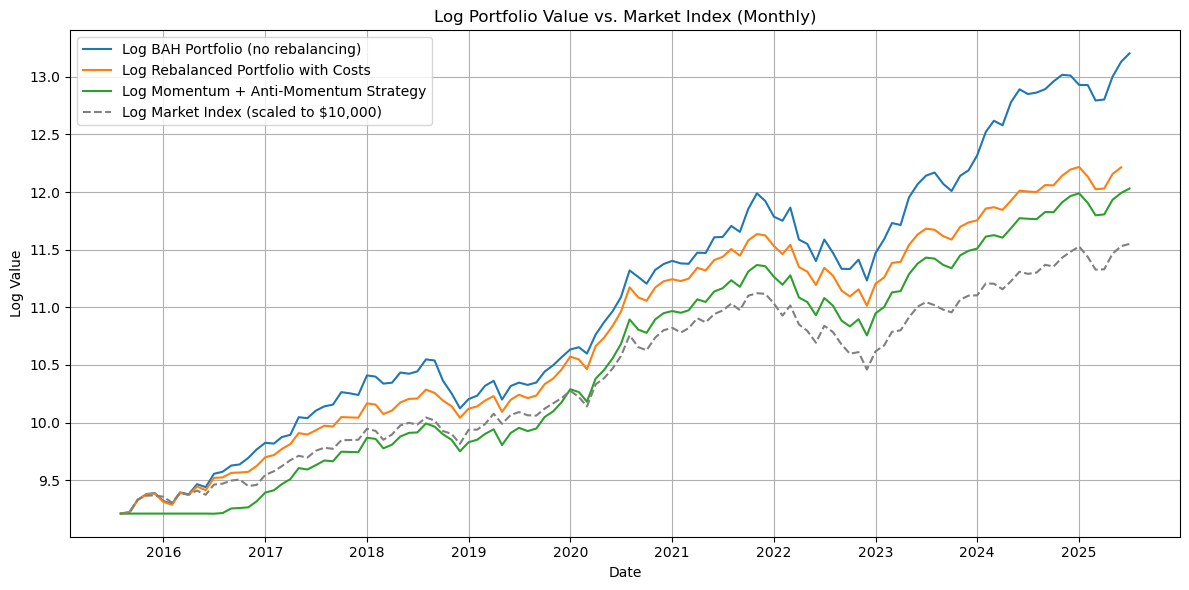

In [12]:
# === 10. Plot volatility momentum against all log values ===

plt.figure(figsize=(12, 6))
plt.plot(np.log(bah_portfolio), label="Log BAH Portfolio (no rebalancing)")
plt.plot(np.log(rebalanced_portfolio_net), label="Log Rebalanced Portfolio with Costs")
plt.plot(np.log(mom_net_raw), label="Log Momentum + Anti-Momentum Strategy")
plt.plot(np.log(market_index), label="Log Market Index (scaled to $10,000)", linestyle="--", color="gray")
plt.title("Log Portfolio Value vs. Market Index (Monthly)")
plt.xlabel("Date")
plt.ylabel("Log Value")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


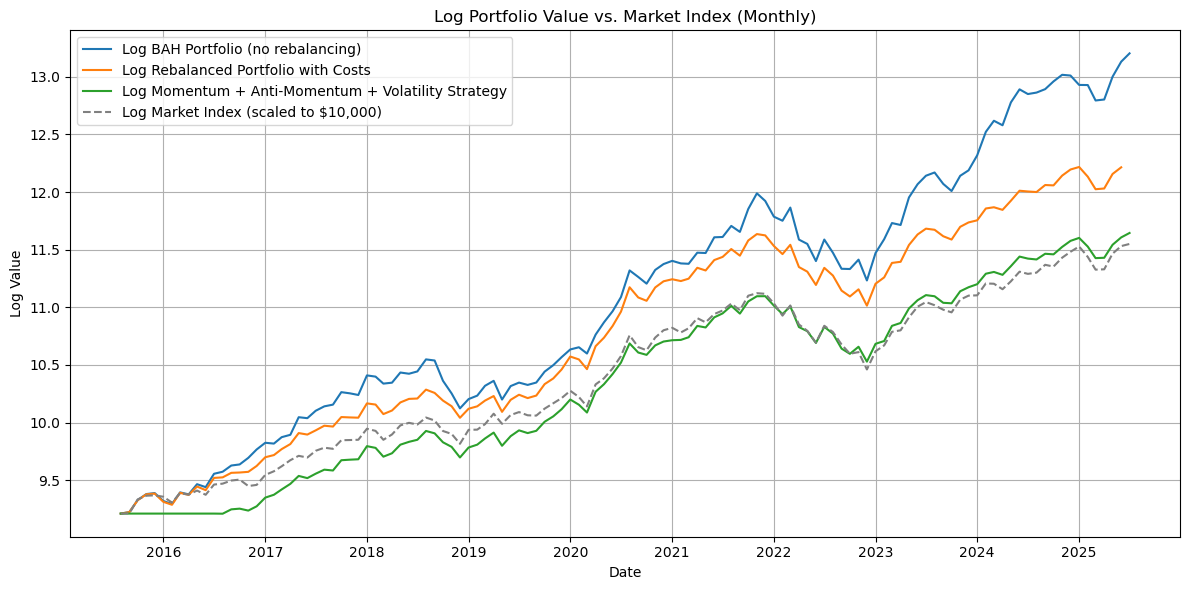

In [13]:
# === 11. Plot volatility momentum against all log values ===

plt.figure(figsize=(12, 6))
plt.plot(np.log(bah_portfolio), label="Log BAH Portfolio (no rebalancing)")
plt.plot(np.log(rebalanced_portfolio_net), label="Log Rebalanced Portfolio with Costs")
plt.plot(np.log(mom_net_vol), label="Log Momentum + Anti-Momentum + Volatility Strategy")
plt.plot(np.log(market_index), label="Log Market Index (scaled to $10,000)", linestyle="--", color="gray")
plt.title("Log Portfolio Value vs. Market Index (Monthly)")
plt.xlabel("Date")
plt.ylabel("Log Value")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

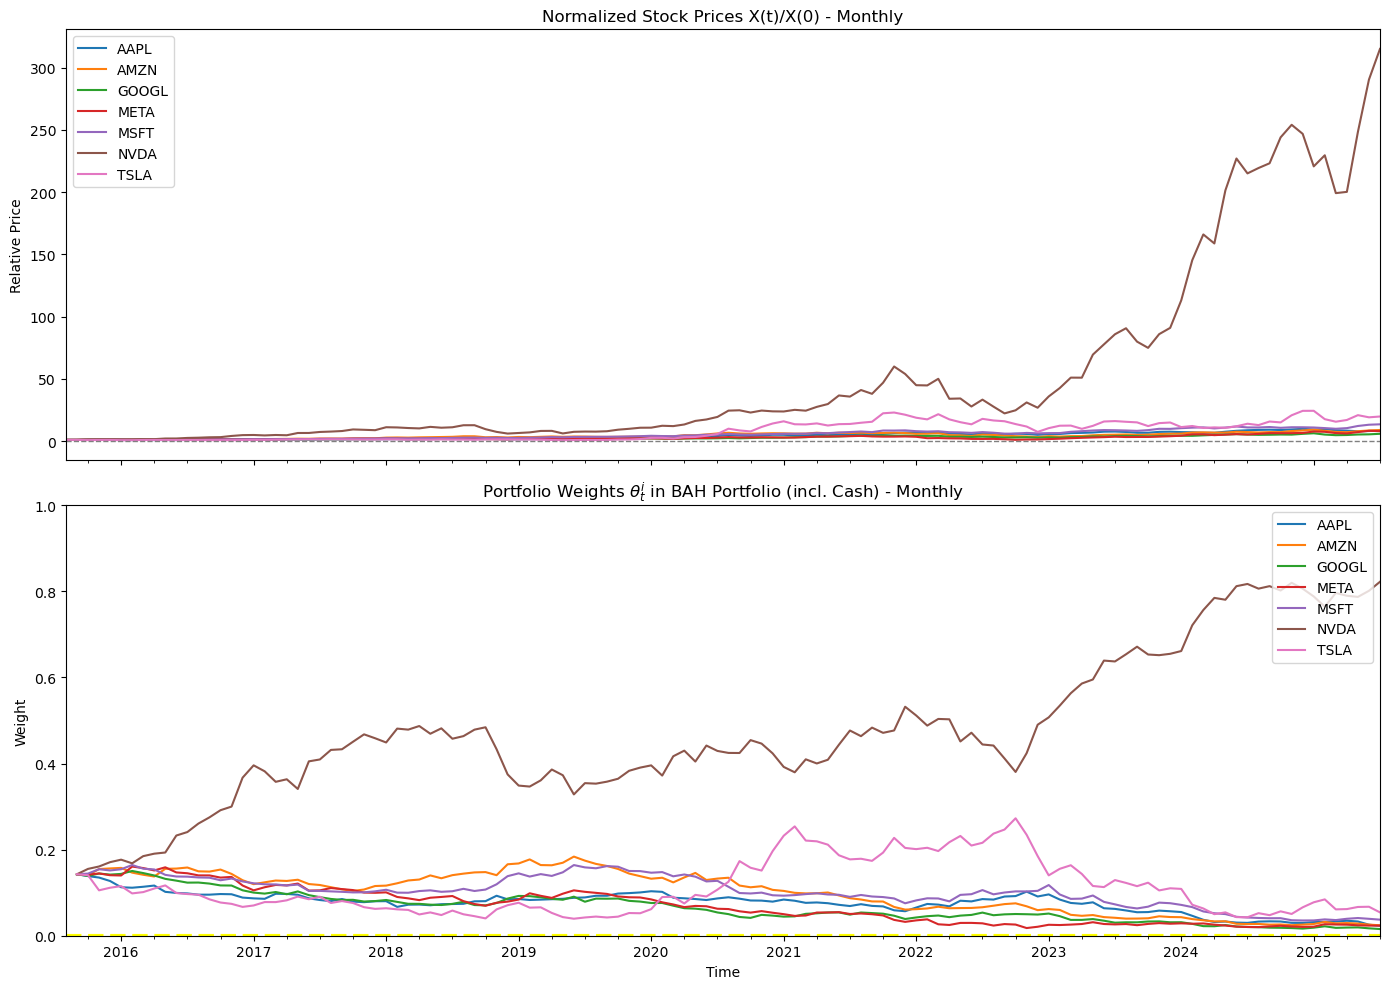

In [14]:
# === 11. Plot of theta time series against individual stock prices ===

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Top plot: normalized stock prices
normalized.plot(ax=ax1)
ax1.axhline(0, color='gray', linestyle='--', linewidth=1)  
ax1.set_title("Normalized Stock Prices X(t)/X(0) - Monthly")
ax1.set_ylabel("Relative Price")
ax1.legend(loc="upper left")

# Bottom plot: theta values + cash position
theta.plot(ax=ax2)
ax2.axhline(0, color='yellow', linestyle='--', linewidth=3)  
ax2.set_title(r"Portfolio Weights $\theta_{t}^i$ in BAH Portfolio (incl. Cash) - Monthly")
ax2.set_ylabel("Weight")
ax2.set_ylim(0, 1)
ax2.legend(loc="upper right")
ax2.set_xlabel("Time")

plt.tight_layout()
plt.show()


In [15]:
# === 12. Compute MDD (maximal drawdown)
def compute_max_drawdown(series):
    running_max = series.cummax()
    drawdown = (series - running_max) / running_max
    max_drawdown = drawdown.min()
    return max_drawdown

In [16]:
# === 13. Compute MDD of each portfolio
mdd_bah = compute_max_drawdown(bah_portfolio)
mdd_rebalanced = compute_max_drawdown(rebalanced_portfolio_net)
mdd_momentum_raw = compute_max_drawdown(mom_net_raw)
mdd_momentum_vol = compute_max_drawdown(mom_net_vol)
mdd_market = compute_max_drawdown(market_index)

In [17]:
print(f"Max Drawdown (BAH):                     {mdd_bah:.2%}")
print(f"Max Drawdown (Rebalanced):              {mdd_rebalanced:.2%}")
print(f"Max Drawdown (Momentum):                {mdd_momentum_raw:.2%}")
print(f"Max Drawdown (Momentum + Volatility):   {mdd_momentum_vol:.2%}")
print(f"Max Drawdown (Market):                  {mdd_market:.2%}")

Max Drawdown (BAH):                     -53.04%
Max Drawdown (Rebalanced):              -46.26%
Max Drawdown (Momentum):                -45.72%
Max Drawdown (Momentum + Volatility):   -43.32%
Max Drawdown (Market):                  -48.40%


In [18]:
def compute_sharpe_ratio(portfolio_values, risk_free_rate=0.0, freq_per_year=12, annualize=True):
    """
    Computes the Sharpe ratio for a portfolio.

    Parameters:
    - portfolio_values (pd.Series): Portfolio value over time (indexed by date).
    - risk_free_rate (float): Risk-free rate per year (e.g., 0.02 for 2%). Default is 0.
    - freq_per_year (int): Number of periods per year (52 for weekly, 252 for daily, 12 for monthly).
    - annualize (bool): Whether to return the annualized Sharpe ratio.

    Returns:
    - Sharpe ratio (float)
    """
    returns = portfolio_values.pct_change().dropna()

    # Convert annual risk-free rate to per-period rate
    rf_per_period = (1 + risk_free_rate) ** (1 / freq_per_year) - 1

    # Excess returns
    excess_returns = returns - rf_per_period

    # Sharpe ratio (non-annualized)
    sharpe = excess_returns.mean() / excess_returns.std()

    if annualize:
        sharpe *= np.sqrt(freq_per_year)

    return sharpe


In [19]:
sharpe_bah = compute_sharpe_ratio(bah_portfolio)
sharpe_rebalanced = compute_sharpe_ratio(rebalanced_portfolio_net)
sharpe_momentum_raw = compute_sharpe_ratio(mom_net_raw)
sharpe_momentum_vol = compute_sharpe_ratio(mom_net_vol)
sharpe_market = compute_sharpe_ratio(market_index)

print(f"Sharpe Ratio (BAH):                     {sharpe_bah:.2f}")
print(f"Sharpe Ratio (Rebalanced):              {sharpe_rebalanced:.2f}")
print(f"Sharpe Ratio (Momentum):                {sharpe_momentum_raw:.2f}")
print(f"Sharpe Ratio (Momentum + Volatility):   {sharpe_momentum_vol:.2f}")
print(f"Sharpe Ratio (Market):                  {sharpe_market:.2f}")


Sharpe Ratio (BAH):                     1.37
Sharpe Ratio (Rebalanced):              1.30
Sharpe Ratio (Momentum):                1.24
Sharpe Ratio (Momentum + Volatility):   1.20
Sharpe Ratio (Market):                  1.08
